In [1]:
import pandas as pd
from pathlib import Path

clean_df = pd.read_csv("../data/clean_index.csv")
folds_df = pd.read_csv("../data/folds.csv")

for name, df in [("clean_index", clean_df), ("folds", folds_df)]:
    print("=" * 60)
    print(name, "| shape:", df.shape)
    print("Columns:", list(df.columns))
    print(df.head(3).to_string())

    # Show value counts for columns with few unique values (labels, folds, splits)
    for col in df.columns:
        if df[col].nunique() <= 10:
            print(f"\nValue counts for '{col}':")
            print(df[col].value_counts().to_string())

clean_index | shape: (491, 3)
Columns: ['path', 'label', 'hash']
                                                                          path label                              hash
0    data/ECG Images of Myocardial Infarction Patients (240x12=2880)/MI(1).jpg    MI  bfec4d7750785b6eabd82d73409c4653
1   data/ECG Images of Myocardial Infarction Patients (240x12=2880)/MI(10).jpg    MI  d300b946e3a4187dd290674bec105cbf
2  data/ECG Images of Myocardial Infarction Patients (240x12=2880)/MI(101).jpg    MI  174ca9e3206bc5b82adc4cba26510b0f

Value counts for 'label':
label
Abnormal         233
Normal           142
History_of_MI     86
MI                30
folds | shape: (491, 4)
Columns: ['path', 'label', 'hash', 'fold']
                                                                          path label                              hash  fold
0    data/ECG Images of Myocardial Infarction Patients (240x12=2880)/MI(1).jpg    MI  bfec4d7750785b6eabd82d73409c4653     4
1   data/ECG Images of My

In [2]:
from pathlib import Path
import hashlib
import pandas as pd

DATA_DIR = Path("../data")
IMG_EXTS = {".jpg", ".jpeg", ".png"}


def folder_to_label(folder_name):
    """Map a raw folder name to a short label (order matters)."""
    name = folder_name.lower()
    if "history" in name:
        return "History_of_MI"
    if "abnormal" in name:
        return "Abnormal"
    if "normal person" in name:
        return "Normal"
    if "myocardial" in name:
        return "MI"
    return None  # ignore any other folder


rows = []
for folder in sorted(DATA_DIR.iterdir()):
    if not folder.is_dir():
        continue
    label = folder_to_label(folder.name)
    if label is None:
        continue
    for p in sorted(folder.iterdir()):
        if p.suffix.lower() in IMG_EXTS:
            rows.append(
                {
                    "path": str(p),
                    "label": label,
                    "hash": hashlib.md5(p.read_bytes()).hexdigest(),
                }
            )

raw_df = pd.DataFrame(rows)

# 1) Raw file count vs unique-content count per class
summary = raw_df.groupby("label").agg(
    total_files=("hash", "size"),
    unique_hashes=("hash", "nunique"),
)
print(summary)

# 2) Hashes that appear in more than one class (label conflicts)
classes_per_hash = raw_df.groupby("hash")["label"].nunique()
print("\nHashes shared across different classes:", (classes_per_hash > 1).sum())

# 3) Fold balance: images per class per fold
folds_df = pd.read_csv("../data/folds.csv")
print("\nImages per class per fold:")
print(pd.crosstab(folds_df["label"], folds_df["fold"]))

               total_files  unique_hashes
label                                    
Abnormal               233            233
History_of_MI          172             86
MI                     239             30
Normal                 284            142

Hashes shared across different classes: 0

Images per class per fold:
fold            0   1   2   3   4
label                            
Abnormal       46  47  47  47  46
History_of_MI  18  17  17  17  17
MI              6   6   6   6   6
Normal         29  28  28  28  29


In [3]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

DATA_DIR = Path("../data")
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
IMG_EXTS = {".jpg", ".jpeg", ".png"}
ORDER = ["Abnormal", "History_of_MI", "MI", "Normal"]


def folder_to_label(name):
    """Map a raw folder name to a short label (order matters)."""
    name = name.lower()
    if "history" in name:
        return "History_of_MI"
    if "abnormal" in name:
        return "Abnormal"
    if "normal person" in name:
        return "Normal"
    if "myocardial" in name:
        return "MI"
    return None


rows = []
for folder in sorted(DATA_DIR.iterdir()):
    label = folder_to_label(folder.name) if folder.is_dir() else None
    if label is None:
        continue
    for p in sorted(folder.iterdir()):
        if p.suffix.lower() in IMG_EXTS:
            rows.append(
                {
                    "path": str(p),
                    "label": label,
                    "hash": hashlib.md5(p.read_bytes()).hexdigest(),
                }
            )

raw_df = pd.DataFrame(rows)
# copies = how many files share this hash; kept = the first file of each hash
raw_df["copies"] = raw_df.groupby("hash")["hash"].transform("size")
raw_df["kept"] = ~raw_df.duplicated(subset="hash", keep="first")
print("files:", len(raw_df), "| unique images:", raw_df["kept"].sum())

files: 928 | unique images: 491


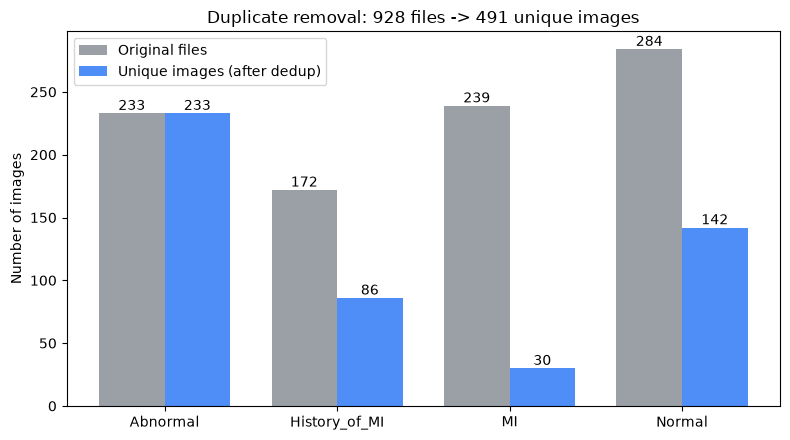

In [4]:
raw_counts = raw_df.groupby("label").size().reindex(ORDER)
unique_counts = raw_df[raw_df["kept"]].groupby("label").size().reindex(ORDER)

x = np.arange(len(ORDER))
w = 0.38
fig, ax = plt.subplots(figsize=(8, 4.5))
b1 = ax.bar(x - w / 2, raw_counts.values, w, label="Original files", color="#9aa0a6")
b2 = ax.bar(
    x + w / 2,
    unique_counts.values,
    w,
    label="Unique images (after dedup)",
    color="#4f8df7",
)
ax.bar_label(b1)
ax.bar_label(b2)
ax.set_xticks(x)
ax.set_xticklabels(ORDER)
ax.set_ylabel("Number of images")
ax.set_title(
    f"Duplicate removal: {len(raw_df)} files -> {int(raw_df['kept'].sum())} unique images"
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_dedup_counts.png", dpi=150)
plt.show()

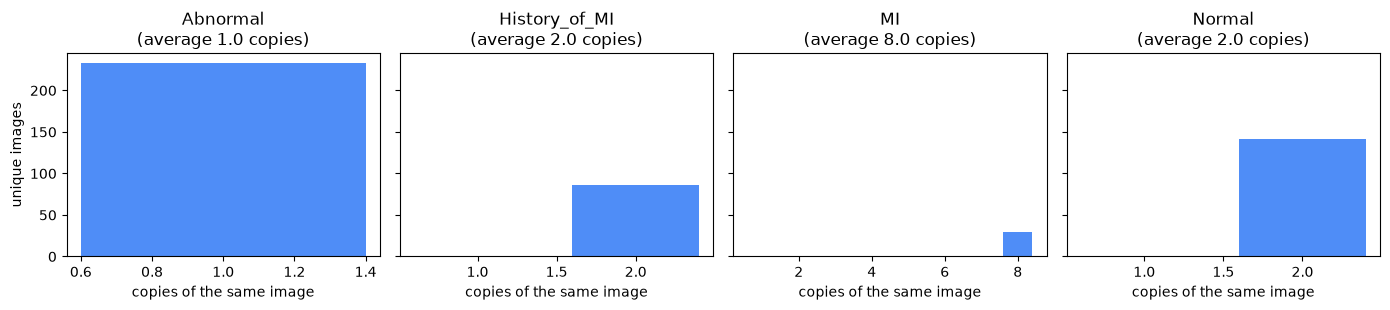

In [7]:
kept = raw_df[raw_df["kept"]]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, label in zip(axes, ORDER):
    c = kept[kept["label"] == label]["copies"]
    ax.hist(c, bins=range(1, int(c.max()) + 2), align="left", color="#4f8df7", rwidth=0.8)
    ax.set_title(f"{label}\n(average {c.mean():.1f} copies)")
    ax.set_xlabel("copies of the same image")
axes[0].set_ylabel("unique images")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_copies_per_image.png", dpi=150)
plt.show()

Hash 087229a165c30dbe751567393acfc610 appears in 8 files:
   MI(102).jpg
   MI(12).jpg
   MI(132).jpg
   MI(162).jpg
   MI(192).jpg
   MI(222).jpg
   MI(42).jpg
   MI(72).jpg


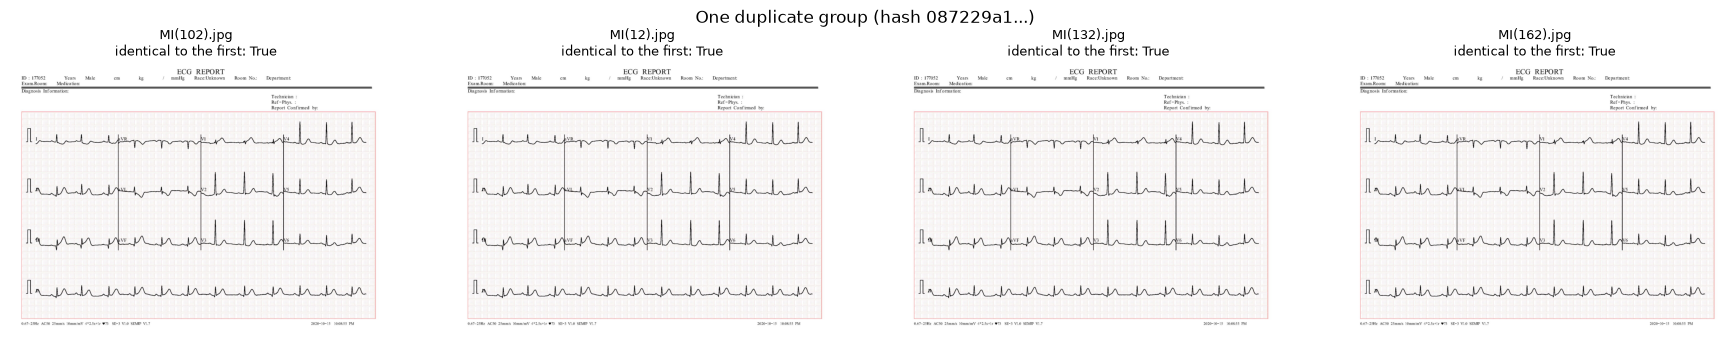

In [8]:
# The MI hash with the most copies
group_hash = (
    raw_df[raw_df["label"] == "MI"]
    .groupby("hash")
    .size()
    .sort_values(ascending=False)
    .index[0]
)
group = raw_df[raw_df["hash"] == group_hash]
print(f"Hash {group_hash} appears in {len(group)} files:")
for p in group["path"]:
    print("  ", Path(p).name)

show = group.head(4)
first_pixels = np.array(Image.open(show.iloc[0]["path"]).convert("L"))

fig, axes = plt.subplots(1, len(show), figsize=(4.5 * len(show), 3.4))
axes = np.atleast_1d(axes)
for ax, (_, r) in zip(axes, show.iterrows()):
    img = Image.open(r["path"])
    same = np.array_equal(np.array(img.convert("L")), first_pixels)
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"{Path(r['path']).name}\nidentical to the first: {same}", fontsize=9)
fig.suptitle(f"One duplicate group (hash {group_hash[:8]}...)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_duplicate_group.png", dpi=150)
plt.show()

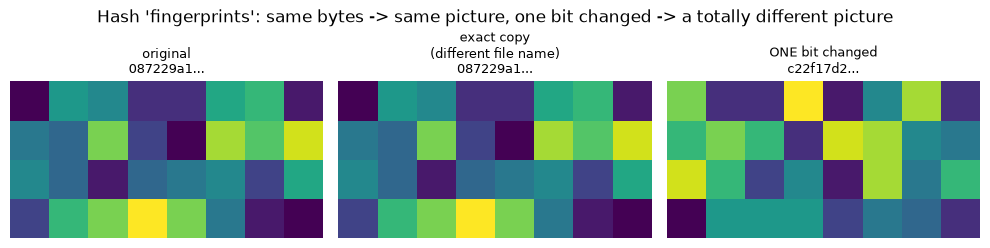

In [9]:
def hash_picture(h):
    """Draw the 32 hex characters of a hash as a 4x8 grid of 16 shades."""
    return np.array([int(c, 16) for c in h]).reshape(4, 8)


data = Path(group.iloc[0]["path"]).read_bytes()
copy_data = Path(group.iloc[-1]["path"]).read_bytes()  # another file, same hash group
changed = bytearray(data)
changed[100] ^= 1  # flip ONE bit of ONE byte

samples = [
    ("original", hashlib.md5(data).hexdigest()),
    ("exact copy\n(different file name)", hashlib.md5(copy_data).hexdigest()),
    ("ONE bit changed", hashlib.md5(bytes(changed)).hexdigest()),
]

fig, axes = plt.subplots(1, 3, figsize=(10, 2.8))
for ax, (title, h) in zip(axes, samples):
    ax.imshow(hash_picture(h), cmap="viridis", vmin=0, vmax=15)
    ax.set_title(f"{title}\n{h[:8]}...", fontsize=9)
    ax.axis("off")
fig.suptitle(
    "Hash 'fingerprints': same bytes -> same picture, one bit changed -> a totally different picture"
)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_hash_fingerprint.png", dpi=150)
plt.show()

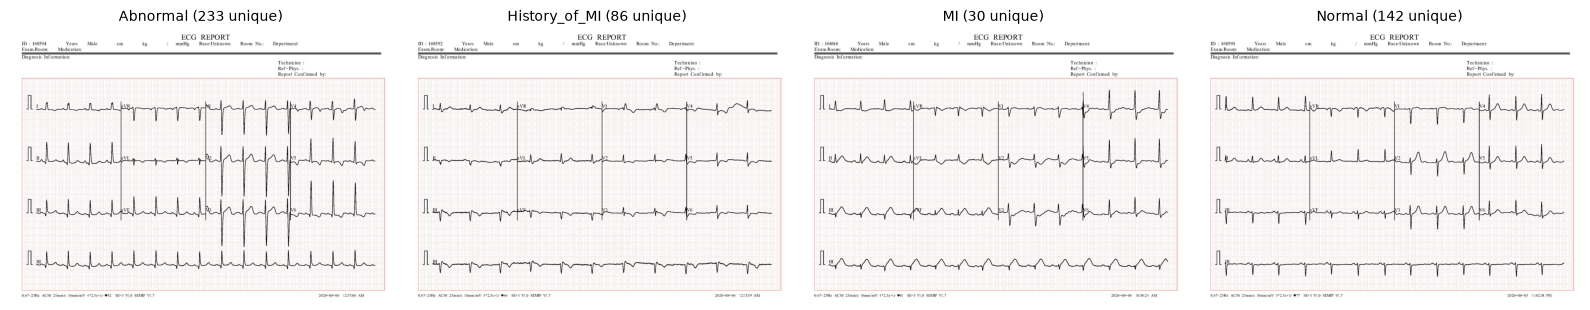

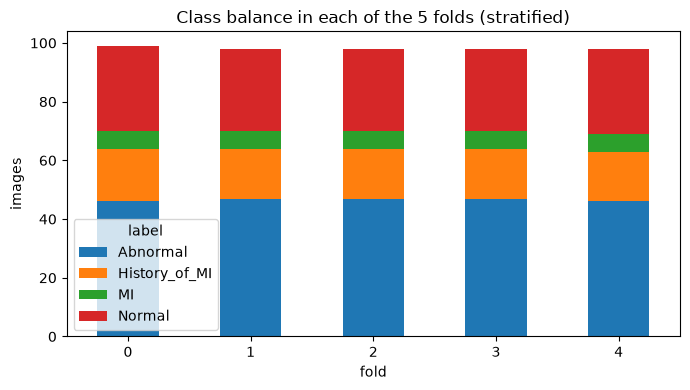

In [10]:
# Visual 5: one sample ECG per class
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, label in zip(axes, ORDER):
    r = kept[kept["label"] == label].iloc[0]
    ax.imshow(Image.open(r["path"]))
    ax.axis("off")
    ax.set_title(f"{label} ({len(kept[kept['label'] == label])} unique)", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_samples.png", dpi=150)
plt.show()

# Visual 6: class balance inside each of the 5 folds
folds_df = pd.read_csv(DATA_DIR / "folds.csv")
ct = pd.crosstab(folds_df["fold"], folds_df["label"])[ORDER]
ax = ct.plot(kind="bar", stacked=True, figsize=(7, 4))
ax.set_xlabel("fold")
ax.set_ylabel("images")
ax.set_title("Class balance in each of the 5 folds (stratified)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_folds.png", dpi=150)
plt.show()